#### **Automotive After-Sales Analytics: Workshop Performance EDA**
* This notebook performs exploratory data analysis (EDA) on the simulated Dealer Management System (DMS) dataset for Suzuki & Citroën operations across UAE branches.

#### **Imports**

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import os

# Display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries loaded successfully!")

Libraries loaded successfully!


#### **Loading Data**

In [2]:
DATA_DIR = "../data/raw"

df_branches = pd.read_parquet(os.path.join(DATA_DIR, "dim_branches.parquet"))
df_technicians = pd.read_parquet(os.path.join(DATA_DIR, "dim_technicians.parquet"))
df_customers = pd.read_parquet(os.path.join(DATA_DIR, "dim_customers.parquet"))
df_vehicles = pd.read_parquet(os.path.join(DATA_DIR, "dim_vehicles.parquet"))
df_bookings = pd.read_parquet(os.path.join(DATA_DIR, "fact_bookings.parquet"))
df_repair_orders = pd.read_parquet(os.path.join(DATA_DIR, "fact_repair_orders.parquet"))
df_crm = pd.read_parquet(os.path.join(DATA_DIR, "fact_crm.parquet"))

print(f"Loaded Branches: {df_branches.shape}")
print(f"Loaded Technicians: {df_technicians.shape}")
print(f"Loaded Customers: {df_customers.shape}")
print(f"Loaded Vehicles: {df_vehicles.shape}")
print(f"Loaded Bookings: {df_bookings.shape}")
print(f"Loaded Repair Orders (ROs): {df_repair_orders.shape}")
print(f"Loaded CRM Interactions: {df_crm.shape}")

Loaded Branches: (7, 6)
Loaded Technicians: (154, 5)
Loaded Customers: (60000, 5)
Loaded Vehicles: (75000, 8)
Loaded Bookings: (150000, 7)
Loaded Repair Orders (ROs): (120000, 12)
Loaded CRM Interactions: (200000, 7)


#### **Executive Summary & Core Financial KPIs**

##### **High-Level Financial & Operational KPIs**
* Let's calculate network-wide totals for Service Revenue (Labor + Parts), Average Revenue per RO, and First-Time Fix Rates (FTFR).

##### **KPI Calculation**

In [3]:
df_ro_merged = df_repair_orders.merge(df_branches, on="branch_id", how="left")

# Calculate total revenue per Repair Orders
df_ro_merged["total_ro_revenue_aed"] = df_ro_merged["labor_revenue_aed"] + df_ro_merged["parts_revenue_aed"]

total_ro_count = len(df_ro_merged)
total_labor_rev = df_ro_merged["labor_revenue_aed"].sum()
total_parts_rev = df_ro_merged["parts_revenue_aed"].sum()
total_network_rev = total_labor_rev + total_parts_rev
avg_rev_per_ro = total_network_rev / total_ro_count
overall_ftfr = (df_ro_merged["first_time_fix_flag"].sum() / total_ro_count) * 100
overall_comeback = (df_ro_merged["comeback_flag"].sum() / total_ro_count) * 100

print("==========================================")
print("     AFTER-SALES EXECUTIVE KPI SUMMARY    ")
print("==========================================")
print(f"Total Completed Repair Orders : {total_ro_count:,}")
print(f"Total Network Revenue         : AED {total_network_rev:,.2f}")
print(f"  - Total Labor Revenue       : AED {total_labor_rev:,.2f}")
print(f"  - Total Parts Revenue       : AED {total_parts_rev:,.2f}")
print(f"Average Revenue per RO        : AED {avg_rev_per_ro:,.2f}")
print(f"First-Time Fix Rate (FTFR)    : {overall_ftfr:.2f}%")
print(f"Comeback Rate                 : {overall_comeback:.2f}%")
print("==========================================")

     AFTER-SALES EXECUTIVE KPI SUMMARY    
Total Completed Repair Orders : 120,000
Total Network Revenue         : AED 390,353,245.45
  - Total Labor Revenue       : AED 140,601,532.58
  - Total Parts Revenue       : AED 249,751,712.87
Average Revenue per RO        : AED 3,252.94
First-Time Fix Rate (FTFR)    : 94.00%
Comeback Rate                 : 6.00%


#### **Branch-Level Performance & Revenue Breakdown**

##### **Branch Performance Analysis (Revenue Yield & RO Volume)**
* Let's evaluate how revenue and repair order volume are distributed across our 7 regional branches in Dubai, Abu Dhabi, Sharjah, RAK, and Fujairah.

##### **Branch Aggregation & Table**

In [11]:
branch_performance = df_ro_merged.groupby("branch_name").agg(
    total_ros=("ro_id", "count"),
    labor_revenue_aed=("labor_revenue_aed", "sum"),
    parts_revenue_aed=("parts_revenue_aed", "sum"),
    total_revenue_aed=("total_ro_revenue_aed", "sum"),
    avg_ro_revenue_aed=("total_ro_revenue_aed", "mean"),
    avg_ftfr_pct=("first_time_fix_flag", lambda x: (x.sum() / len(x)) * 100),).reset_index()

branch_performance["labor_share_pct"] = (branch_performance["labor_revenue_aed"]/ branch_performance["total_revenue_aed"]) * 100
branch_performance["parts_share_pct"] = (branch_performance["parts_revenue_aed"]/ branch_performance["total_revenue_aed"]) * 100

branch_performance.sort_values(by="total_revenue_aed", ascending=False, inplace=True)
branch_performance.reset_index(drop=True, inplace=True)

# Save to processed folder
os.makedirs("../data/processed", exist_ok=True)
branch_performance.to_parquet( "../data/processed/branch_performance.parquet", index=False)

display(branch_performance)

,branch_name,total_ros,labor_revenue_aed,parts_revenue_aed,total_revenue_aed,avg_ro_revenue_aed,avg_ftfr_pct,labor_share_pct,parts_share_pct
0,Dubai - Al Quoz (Flagship),38324,44602768.39,79320377.03,123923145.42,3233.57,93.95,35.99,64.01
1,Abu Dhabi - Mussafah M13,26419,30990636.27,55170695.82,86161332.09,3261.34,94.02,35.97,64.03
2,Dubai - Deira,21700,25529631.43,45091929.96,70621561.39,3254.45,94.00,36.15,63.85
3,Sharjah - Industrial Area 17,14243,16841741.59,29974981.92,46816723.51,3287.00,93.67,35.97,64.03
4,Al Ain - Industrial Area,9599,11274811.34,19997194.98,31272006.32,3257.84,94.27,36.05,63.95
5,Ras Al Khaimah - Sheikh Mohamed Bin Salem,6027,7067920.52,12538061.94,19605982.46,3253.03,94.61,36.05,63.95
6,Fujairah - Madhab,3688,4294023.04,7658471.22,11952494.26,3240.91,93.84,35.93,64.07


#### **Workshop Efficiency & Technician Productivity**

##### **Technician Productivity & Efficiency Analysis**
* Analyzing billed flat-rate hours vs. actual clocked hours. Technician Efficiency = (Sold Hours / Clocked Hours) * 100.

##### **Technician Metrics**

In [12]:
os.makedirs("../data/processed", exist_ok=True)

# Merge Repair Orders with Technician skill level only
tech_summary = df_repair_orders.merge(df_technicians[["technician_id", "skill_level"]], on="technician_id",  how="left")

tech_perf = tech_summary.groupby(["technician_id", "branch_id", "skill_level"]).agg(total_jobs=("ro_id", "count"),
 total_sold_hours=("sold_labor_hours", "sum"),total_clocked_hours=("actual_clocked_hours", "sum")).reset_index()

tech_perf["technician_efficiency_pct"] = (tech_perf["total_sold_hours"] / tech_perf["total_clocked_hours"]) * 100

# Save processed results to data/processed folder
tech_perf.to_parquet("../data/processed/technician_performance.parquet", index=False)

print("Top 5 Most Efficient Technicians:")
display(tech_perf.sort_values(by="technician_efficiency_pct", ascending=False).head(5))

print("\nAverage Efficiency by Skill Level:")
display(tech_perf.groupby("skill_level")["technician_efficiency_pct"].mean().reset_index())

Top 5 Most Efficient Technicians:


,technician_id,branch_id,skill_level,total_jobs,total_sold_hours,total_clocked_hours,technician_efficiency_pct
881,TECH-126,7,Junior,18,127.20,118.70,107.16
167,TECH-024,7,Junior,16,136.50,127.90,106.72
580,TECH-083,7,Junior,21,111.80,105.80,105.67
321,TECH-046,7,Senior,22,169.00,161.00,104.97
636,TECH-091,7,Junior,22,206.70,197.40,104.71



Average Efficiency by Skill Level:


,skill_level,technician_efficiency_pct
0,Junior,100.02
1,Master Technician,100.08
2,Senior,100.00


#### **Plotly Visualizations for Executive Presentation**

##### **Interactive Visualizations**
* Let's generate Plotly charts for branch revenue breakdown and job type distributions.

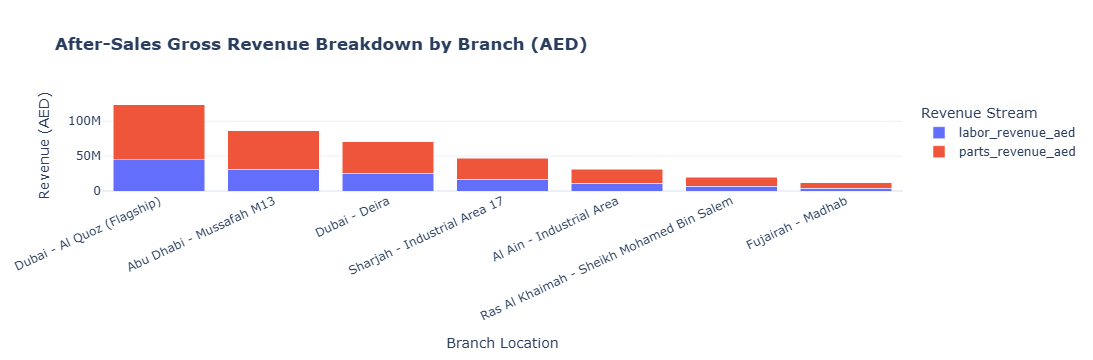

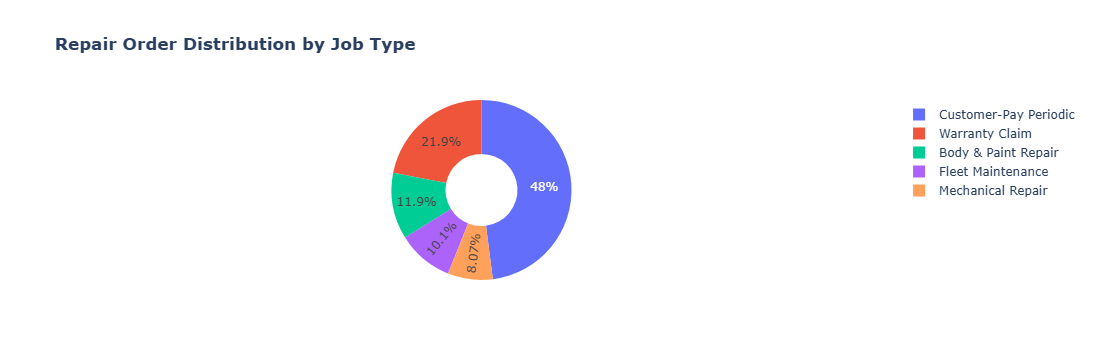

In [10]:
os.makedirs("../docs", exist_ok=True)

# 1. Branch Revenue Bar Chart
fig_branch = px.bar(
    branch_performance,
    x="branch_name",
    y=["labor_revenue_aed", "parts_revenue_aed"],
    title="<b>After-Sales Gross Revenue Breakdown by Branch (AED)</b>",
    labels={
        "value": "Revenue (AED)",
        "branch_name": "Branch Location",
        "variable": "Revenue Stream",
    },
    barmode="stack",
    template="plotly_white",
)
fig_branch.update_layout(xaxis_tickangle=-25)
fig_branch.write_html("../docs/branch_revenue_breakdown.html")
fig_branch.show()

# 2. Job Type Distribution Pie Chart
job_type_counts = df_repair_orders["job_type"].value_counts().reset_index()
job_type_counts.columns = ["job_type", "count"]

fig_jobs = px.pie(
    job_type_counts,
    names="job_type",
    values="count",
    title="<b>Repair Order Distribution by Job Type</b>",
    hole=0.4,
    template="plotly_white",
)
fig_jobs.write_html("../docs/repair_order_distribution.html")
fig_jobs.show()